# Arabic Semantic Poetry Retrieval
## مشروع الاسترجاع الدلالي للشعر العربي

Describe a person in Arabic and choose a poetry genre. The system retrieves **three existing bayt candidates**, each containing two supplied hemistichs, with poet, source and similarity.

**Inputs:** الوصف أو السيرة + الغرض الشعري  
**Genres:** مدح، هجاء، غزل، فخر، رثاء، عتاب


## Step 1 — Understand the pipeline

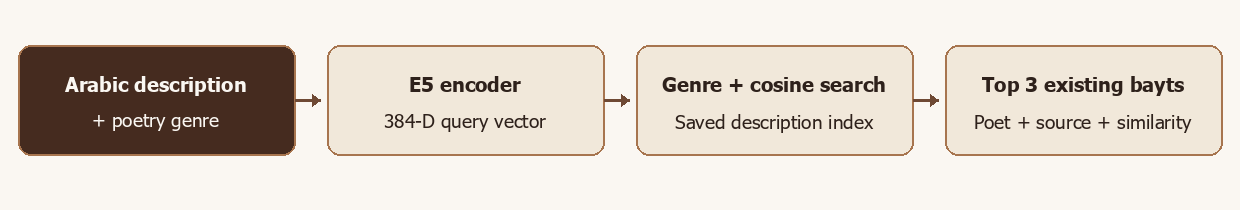

E5 converts the description into a vector. The system searches the saved index within the selected genre and returns the highest-ranked distinct verse texts. It does not write new poetry.


## Step 2 — Connect to the existing project

Run this notebook with the project dependencies available. Set `ROOT` to the project folder if automatic detection fails. Existing files are reused; nothing is downloaded or rebuilt.


In [ ]:
from pathlib import Path
import os, json
import pandas as pd
from IPython.display import display, HTML

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "app.py").exists())
ARTIFACTS = Path(os.environ.get("ARABIC_POETRY_ARTIFACTS", str(ROOT)))
DATA = ARTIFACTS / "data"
assert (DATA / "original_records.jsonl").exists(), "Provide an authorized artifact bundle; see data/README.md."


## Step 3 — Look at the poetry data

The corpus contains **3,000 imported records**, with **500 per genre**. Original verse text is kept separately from its AI-proposed description. Attribution, genre labels and source permissions retain their existing verification status.


In [ ]:
records = [json.loads(line) for line in
           (DATA / "original_records.jsonl").read_text(encoding="utf-8").splitlines()]
print("Records:", len(records))
print("Genres:", pd.Series(r["genre"] for r in records).value_counts().to_dict())
display(pd.DataFrame(records)[["genre", "poet", "hemistich_1", "hemistich_2"]].head(3))


## Step 4 — Run a real semantic search

The existing application uses **pretrained `intfloat/multilingual-e5-small`**, a saved **3,000 × 384** description index, genre filtering and cosine similarity. E5 uses `query: ` and `passage: ` prefixes, masked mean pooling and L2 normalization.

Start the local application once from the project root if it is not running:

```powershell
python app.py --port 7860
```

Change only the two inputs below. This reuses the running model instead of loading another copy into RAM.


In [ ]:
from gradio_client import Client

description = "شخص كريم يساعد المحتاجين ويشتهر بحسن الضيافة."
genre = "مدح"
app = Client("http://127.0.0.1:7860", verbose=False)
result = app.predict(description, genre, api_name="/retrieve")
display(HTML(result))


## Step 5 — Read the evaluation correctly

- **Hit@1:** whether the first result is relevant.
- **MRR@10:** how early the first relevant result appears.
- **nDCG@10:** graded relevance, giving more weight to earlier results.

The saved comparison uses **three answerable AI-authored/AI-judged development queries** with depth-ten pooling. It is provisional, not an independent accuracy benchmark. No new experiment is run by this cell.

E5-description is the default because it performed best on top-one success and MRR in this small pool. Other methods can perform better on different criteria. The model was **not fine-tuned on this corpus**.


In [ ]:
path = ROOT / "evaluation/metrics.json"
evaluation = json.loads(path.read_text(encoding="utf-8"))
scores = pd.DataFrame(evaluation["results"])
display(scores[["method", "hit@1", "mrr@10", "ndcg@10"]].round(4))
